In [3]:
%matplotlib inline 

In [4]:
import os
import io
import re
import pandas as pd
import json

In [28]:
#work_fldr = r'D:\Users\Work\OneDrive - Transport Systems Catapult\Research\PhD\Models\tripchains_from_od'
#work_fldr = r'C:\Users\haris.ballis\OneDrive - Transport Systems Catapult\Research\PhD\Models\tripchains_from_od'
#work_fldr = r'C:\Users\Work\Desktop\local_optimisation\tripchains_from_od'
#work_fldr = r'/mnt/sda1/Users/Linux/OneDrive/PhD/Models/tcs_od'
work_fldr = r'C:\Users\haris.ballis\PycharmProjects\tcs_od'

data_source = 'mnd_TSC'
model_name = 'allPop'
trips_direction = 'test'
distr_contr_enabled_switch = [True, False]

tolerance = 0.05

# Dimensions used for the distribution comparison. List should have same order as in main function (of full script)
#distr_dims = ['NumLegs', 'DistanceGroup']#, 'TimePeriodStart', 'TimePeriodEnd']

global_separator = '-'

In [6]:
def prepare_paths(run_results_fldr):

    paths = dict()
    #paths['zones_info'] = os.path.join(run_results_fldr, 'zones_info.csv')
    paths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    paths['tripchains_descr'] = os.path.join(run_results_fldr, 'tripchains_descr.csv')
    paths['tripchains_info'] = os.path.join(run_results_fldr, 'tripchains_info.csv')
    paths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    paths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')

    return paths

In [7]:
def get_optimisation_results(infilepath):
    with open(infilepath) as f:
        data = json.load(f)

        results = data['Solution'][1]['Variable']

        df_data = list()
        for chain, val in results.items():
            cid = re.search('\[(\d+)\]', chain, re.DOTALL).group(1)
            times_used = val['Value']
            df_data.append([int(cid), times_used])

        df = pd.DataFrame(df_data, columns=['TripChainId', 'TimesUsed']).set_index('TripChainId').squeeze()
        return df

In [8]:
def convert_optimisation_output_to_trips(tcs_descr, optim_output):
    # Calculate how many times the tripchain has been used by the optimiser 
    df = tcs_descr.join(optim_output, how='right')
    grpby_cols = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    optimisation_trips = df.groupby(grpby_cols)['TimesUsed'].sum().squeeze()
    optimisation_trips.name = 'OptimisationTrips'
    return optimisation_trips


In [9]:
def get_optimisation_trips(paths):
    
    tcs_descr = pd.read_csv(paths['tripchains_descr'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(paths['optimisation_results'])
    
    if optim_output is not None:
        optimisation_trips = convert_optimisation_output_to_trips(tcs_descr, optim_output)
        return optimisation_trips, optim_output
    else:
        return None

In [10]:
def include_run_info(df, legs, trips_thresh, distr_constr_enabled):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    df['MaxLegs'] = int(legs)
    df['TripsThresh'] = int(trips_thresh)
    df['DistrConstr'] = distr_constr_enabled
    df.set_index(['MaxLegs', 'TripsThresh', 'DistrConstr'], append=True, inplace=True)
    df = df.squeeze()
    
    return df

In [11]:
def prepare_ods_comparison(optim_ods, init_ods):
    comp = init_ods.to_frame().join(optim_ods)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [12]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [13]:
def prepare_ditribution_comparison(fldrpaths):
    tcs_info = pd.read_csv(fldrpaths['tripchains_info'], index_col=['TripChainId'])
    optim_output = get_optimisation_results(fldrpaths['optimisation_results'])
    observed_distr = pd.read_csv(fldrpaths['observed_distribution'], index_col='DistrGroupId')
    observed_distr.drop(columns=['Size'], inplace=True)

    df = tcs_info.join(optim_output, how='right')
    optim_distr = df.groupby('DistrGroupId')['TimesUsed'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in observed_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    observed_distr.set_index(idx_cols, append=True, inplace=True)
    observed_distr = observed_distr.squeeze()
    
    distr_comp = observed_distr.to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['Observed', 'Estimated']
    distr_comp.columns.name = 'Source'
    distr_comp = distr_comp.stack()
    distr_comp.name = 'Percentage'

    return distr_comp

In [14]:
##### MAIN
generation_inputs_fldr = os.path.join(work_fldr, r'generation/inputs')

results_fldr = os.path.join(work_fldr, r'generation/outputs', r'{}/{}/{}'.format(data_source, model_name, trips_direction))
inputs = get_input_params_from_folder(results_fldr)

concat_optim_od = list()
concat_optim_nchains = list()
concat_init_ods = list()
concat_distr_comps = list()

for legs, trips_thresh, distr_constr_enabled in inputs:

    run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
    run_results_fldr = os.path.join(results_fldr, run_tmplt)
    
    fldrpaths = prepare_paths(run_results_fldr)

    optim_od, optim_nchains = get_optimisation_trips(fldrpaths)

    if optim_od is None:
        print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
        continue

    optim_od = include_run_info(optim_od, legs, trips_thresh, distr_constr_enabled)
    optim_nchains = include_run_info(optim_nchains, legs, trips_thresh, distr_constr_enabled)

    concat_optim_od.append(optim_od)
    concat_optim_nchains.append(optim_nchains)

    idx_cols_od = ['OrigZoneId', 'DestZoneId', 'Purpose', 'TimePeriod']
    init_od = pd.read_csv(fldrpaths['od'], index_col=idx_cols_od)
    init_od.drop(columns=['LegId'], inplace=True)
    init_od = include_run_info(init_od, legs, trips_thresh, distr_constr_enabled)
    concat_init_ods.append(init_od)

    distr_comp = prepare_ditribution_comparison(fldrpaths) 
    distr_comp = include_run_info(distr_comp, legs, trips_thresh, distr_constr_enabled)
    concat_distr_comps.append(distr_comp)

optim_nchains = pd.concat(concat_optim_nchains)

ods_optim = pd.concat(concat_optim_od)
ods_init = pd.concat(concat_init_ods)

comp_distrs = pd.concat(concat_distr_comps)
comp_ods = prepare_ods_comparison(ods_optim, ods_init)

#zones_info = pd.read_csv(fldrpaths['zones_info'], index_col=['ZoneId'])

#trips_comparison = trips_comparison.reorder_levels(['Legs', 'TripsThresh', 'DistrConstr', 'LegId'])
#trips_comparison.columns.name = 'TripsSource'
#trips_comparison = trips_comparison.stack()
#trips_comparison.name = 'Trips'
#trips_comparison.to_csv('tmp.csv', header=True)

C:\Users\haris.ballis\AppData\Local\Continuum\anaconda3\lib\site-packages\numpy\lib\arraysetops.py:472: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)
C:\Users\haris.ballis\AppData\Local\Continuum\anaconda3\lib\site-packages\numpy\lib\arraysetops.py:472: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)


In [15]:
#optim_nchains.to_csv(r'./outputs/optimisation_results.csv', header=True, index=True)
#comp_distrs.to_csv(r'./outputs/comparison_distributions_latest.csv', header=True, index=True)
#comp_ods.to_csv(r'./outputs/comparison_od_latest.csv'.format(data_source, model_name, trips_direction), header=True)

In [21]:
df = comp_distrs.copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Estimated)


df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df['BelowTolerance'].all()

False

In [25]:
df = comp_distrs.copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Source')
df['Diff_perc'] = df.Observed.sub(df.Estimated)
df

,,,,Source,Estimated,Observed,Diff_perc
DistrGroupId,DistanceGroup,Legs,MaxLegs,TripsThresh,,,
0,"(0.0, 900.0]",2,3,1,0.129901,0.128918,-0.000983
1,"(0.0, 900.0]",3,3,1,NaN,0.000540,NaN
2,"(900.0, 1800.0]",2,3,1,0.522704,0.533368,0.010665
3,"(900.0, 1800.0]",3,3,1,NaN,0.018332,NaN
4,"(1800.0, 3600.0]",2,3,1,0.220106,0.232444,0.012338
5,"(1800.0, 3600.0]",3,3,1,0.127289,0.084750,-0.042539
6,"(3600.0, inf]",2,3,1,NaN,0.000222,NaN
7,"(3600.0, inf]",3,3,1,NaN,0.001426,NaN


In [29]:
df = comp_ods.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr', 'TripsSource', 'Purpose']).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.DailyTrips - df.OptimisationTrips
df['Diff_perc'] = df.OptimisationTrips/df.DailyTrips - 1

df.style.format({
    'OptimisationTrips': '{:,.0f}'.format,
    'DailyTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [23]:
optim_nchains.groupby(level=[1,2,3]).sum()

MaxLegs  TripsThresh  DistrConstr
3        1            False          70311.0
                      True           71970.0
Name: TimesUsed, dtype: float64

(3, 1, False)
(3, 1, True)


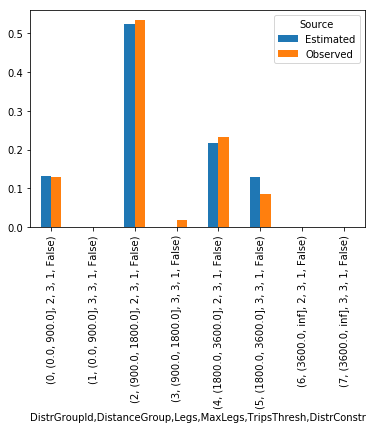

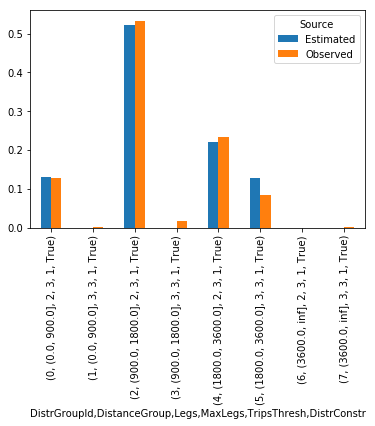

In [24]:
dfg = comp_distrs.groupby(level=['MaxLegs', 'TripsThresh', 'DistrConstr'])
for k, g in dfg:
    print(k)
    plt = g.unstack('Source')
    plt.plot(kind='bar')